# Evolving Soft-Robot Locomotion — Research Archive
### A MuJoCo re-implementation of Cheney et al. 2013 ("Unshackling Evolution"), with quality-diversity search and co-evolved gaits

**Abstract.** We evolve voxel-based soft robots (bodies painted by a CPPN+NEAT genome) to
locomote forward, simulated in MuJoCo. Starting from a long-standing plateau at ~1.08
body-lengths (BL), a multi-lever audit produced a **co-evolved traveling-wave gait**
(`--evolve-gait`) whose best seed reached **1.12 BL in 300 generations** — matching the old
1000-generation record in less than a third of the compute. A single lucky seed of a
stiff-material variant hit **1.3057 BL**, but **multi-seed replication dissolved it**: across
three seeds the stiff-bias config averaged 1.06 BL — statistically identical to its no-stiff-bias
control (1.05) but with 2.6x the variance. That negative is the most useful result in the study,
and it exposes the two facts that now steer the project: **(1) seed-to-seed variance (~1.7x on a
fixed config) is larger than any lever effect measured so far**, and **(2) max fitness plateaus
by generation ~150-200 in every run — the ceiling near ~1.1 BL is architectural, not a matter of
compute.** This notebook archives every run, its configuration, seed-resolved fitness curves, and
rendered champions, plus the key engineering negatives (a native-deformable "flex" engine that is
140x faster but a locomotion dead-end, and an unstable hand-rolled mass-spring engine).

*Generated automatically from `results/`. Re-run cells to regenerate charts/GIFs.*

## 1. Setup

In [1]:
import json, glob, os
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def curve(name, key='max_fitness'):
    # Return (generations, metric) for a run from its per-gen JSON logs.
    # NOTE: sort NUMERICALLY. Plain sorted() is lexicographic, which puts gen_1000
    # straight after gen_100 and scrambles every 1000-generation run's curve.
    import re
    fs = sorted(glob.glob(f'results/{name}/gen_*.json'),
                key=lambda p: int(re.search(r'gen_(\d+)\.json', p).group(1)))
    xs, ys = [], []
    for f in fs:
        d = json.load(open(f))
        xs.append(d.get('iteration', d.get('generation')))
        ys.append(d.get(key, d.get('best_fitness')))
    return xs, ys

plt.rcParams['figure.figsize'] = (9, 5); plt.rcParams['figure.dpi'] = 110

## 2. Results — the discovery arc, then the replication that corrected it

All runs use **MAP-Elites** (quality-diversity) on the **tendon** physics engine, pop 50 x gen 300.
This section is deliberately told in two passes: **how the numbers looked as we found them**, then
**what survived a proper multi-seed test**. The gap between the two is the main lesson.

**Pass 1 — the single-seed discovery arc (seed 1 only).** Adding one lever at a time, each result
beat the last, and it looked like a clean +21% climb:

| run | levers (each adds one) | gen | best BL (seed 1) |
|---|---|---|---|
| `gait_qd3_1000` | material gait, uniform parent | 1000 | 1.0779 |
| `tendon_ctrl`   | material gait, **biased parent** | 300 | 1.0303 |
| `tendon_eg`     | **evolvable gait** + biased | 300 | 1.1195 |
| `tendon_stiff`  | evolvable gait + biased + **stiff-bias 0.3** | 300 | 1.3057 |

**Pass 2 — the same two configs, run across multiple seeds.** The "record" evaporates:

| config | seeds | best per seed | **mean** | std | spread |
|---|---|---|---|---|---|
| **evolve-gait + biased** (control) | 1, 2 | 1.1195 / 0.9837 | **1.052** | 0.096 | 1.14x |
| **+ stiff-bias 0.3** | 1, 2, 3 | 1.3057 / 0.7786 / 1.0880 | **1.057** | 0.265 | **1.68x** |

The two configurations have **the same mean** (1.057 vs 1.052, a 0.5% difference — noise). Paired
by seed, stiff-bias *won* seed 1 by +0.19 but *lost* seed 2 by −0.21 (mean paired difference −0.01,
a coin flip) — while carrying **2.6x the variance**. So the 1.3057 was not a record; it was the
lucky top of a wide, noisy distribution centred on the same place as the control. Reported honestly,
the best **reproducible** result is the evolve-gait config at **~1.05 mean / 1.12 best-seed**.

> **Why this matters more than the headline number:** the seed spread (~1.7x) is *larger than every
> lever effect we measured*. That retroactively puts even the `--evolve-gait` "+8.7%" inside the
> noise band (note `tendon_eg` seed 2 = 0.98 actually fell *below* the material `tendon_ctrl` seed 1
> = 1.03). Evolve-gait keeps a mechanistic story and a separate flex-engine win, so we don't discard
> it — but on tendon it is **not yet cleanly confirmed**. Lesson for everything downstream: screen
> at 3+ seeds, and treat anything under ~1.5x as unproven.

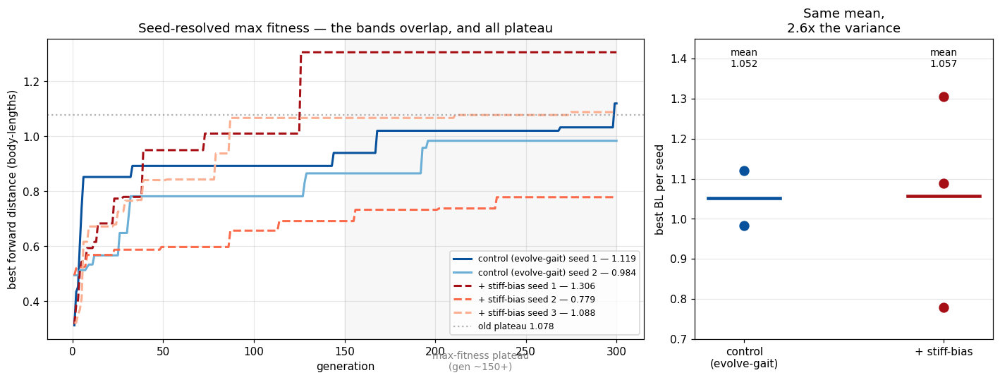

In [2]:
import numpy as np
# Seed-resolved curves grouped by config. Control = evolve-gait+biased (blues);
# stiff-bias variant (reds). The bands OVERLAP and every curve PLATEAUS by gen ~150-200.
control = {'tendon_eg': 'seed 1', 'tendon_eg_s2': 'seed 2'}
stiff   = {'tendon_stiff': 'seed 1', 'tendon_stiff_s2': 'seed 2', 'tendon_stiff_s3': 'seed 3'}
c_blues = ['#08519c', '#6baed6']
c_reds  = ['#a50f15', '#fb6a4a', '#fcae91']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [2, 1]})

for (name, sd), col in zip(control.items(), c_blues):
    xs, ys = curve(name)
    if xs: ax1.plot(xs, ys, color=col, lw=2, label=f'control (evolve-gait) {sd} — {max(ys):.3f}')
for (name, sd), col in zip(stiff.items(), c_reds):
    xs, ys = curve(name)
    if xs: ax1.plot(xs, ys, color=col, lw=2, ls='--', label=f'+ stiff-bias {sd} — {max(ys):.3f}')
ax1.axhline(1.0779, ls=':', c='gray', alpha=.6, label='old plateau 1.078')
ax1.axvspan(150, 300, color='gray', alpha=.06)
ax1.text(225, 0.15, 'max-fitness plateau\n(gen ~150+)', ha='center', color='gray', fontsize=9)
ax1.set_xlabel('generation'); ax1.set_ylabel('best forward distance (body-lengths)')
ax1.set_title('Seed-resolved max fitness — the bands overlap, and all plateau')
ax1.legend(fontsize=8); ax1.grid(alpha=.3)

# Right panel: same mean, different variance.
ctrl_v  = [1.1195, 0.9837]
stiff_v = [1.3057, 0.7786, 1.0880]
ax2.scatter([0]*len(ctrl_v),  ctrl_v,  s=70, color=c_blues[0], zorder=3)
ax2.scatter([1]*len(stiff_v), stiff_v, s=70, color=c_reds[0],  zorder=3)
for x, vals, col in [(0, ctrl_v, c_blues[0]), (1, stiff_v, c_reds[0])]:
    m = np.mean(vals)
    ax2.plot([x-0.18, x+0.18], [m, m], color=col, lw=3)
    ax2.text(x, 1.38, f'mean\n{m:.3f}', ha='center', fontsize=9)
ax2.set_xticks([0, 1]); ax2.set_xticklabels(['control\n(evolve-gait)', '+ stiff-bias'])
ax2.set_ylim(0.7, 1.45); ax2.set_ylabel('best BL per seed')
ax2.set_title('Same mean,\n2.6x the variance'); ax2.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()

## 3. Champion gallery — the convergent solution

The revealing part: across *every* high-fitness run — different levers, different seeds, distances
from 0.78 to 1.31 BL — the winning robot is **the same thing**: a **300-voxel single-material muscle
blob** whose entire locomotion comes from an **evolved traveling-wave gait**, not from body shape.
Material composition of the five champions below:

| champion | best BL | body | stiff voxels | evolved gait `[kx,ky,kz,offset]` |
|---|---|---|---|---|
| `tendon_ctrl` | 1.03 | 300 muscle | 0 | (material gait, no evolved wave) |
| `tendon_eg` | 1.12 | 300x phase-180 | 0 | `[0.49, -0.55, -0.04, 6.12]` |
| `tendon_stiff` (lucky max) | 1.31 | 300x phase-0 | **0** | `[0.34, -0.49, 0.09, 0.89]` |
| `tendon_stiff_s2` | 0.78 | 300x phase-0 | **0** | `[0.51, 0.58, 0.20, 3.19]` |
| `afpo_stiff` | 0.9993 | 300x phase-180 | **0** | (AFPO variant) |

Two things fall out of this table. **(a)** The evolvable gait *sidesteps the classic body-encoder
problem* — a single-material blob (historically a failure mode) locomotes fine when the phase
gradient is supplied from the *control* side instead of the body. **(b)** `--stiff-bias` never
produced a single stiff voxel in any champion: selection strips stiff material out immediately
because it cannot actuate. Whatever the flag does to the *search*, it is emphatically not "adds
rigid structure." The bodies are interchangeable; the **gait genes** are doing all the work — which
is exactly why the next gains have to come from richer control/structure, not from this body knob.

**pvp_long — 1.3384 BL — 1000 gen, 500 voxels, per-voxel phase — PROJECT BEST**

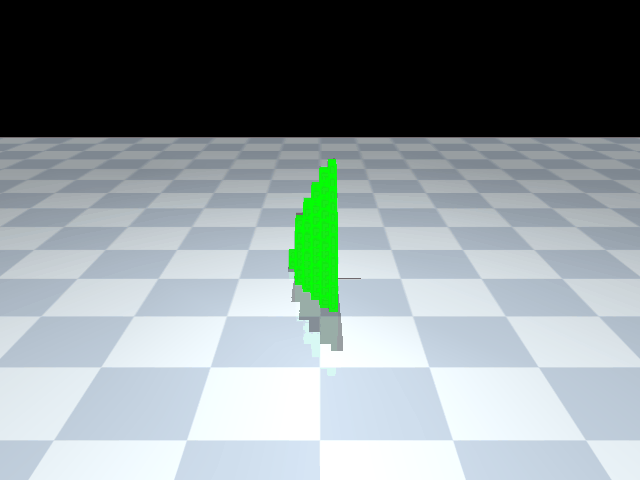

In [3]:
display(Markdown('**pvp_long — 1.3384 BL — 1000 gen, 500 voxels, per-voxel phase — PROJECT BEST**')); display(Image(filename='results/pvp_long/champion.gif' if os.path.exists('results/pvp_long/champion.gif') else 'results/pvp_long.gif')) if (os.path.exists('results/pvp_long/champion.gif') or os.path.exists('results/pvp_long.gif')) else print('gif missing')

**pvp_s1 — 1.3201 BL — per-voxel phase, 300 gen (validated lever)**

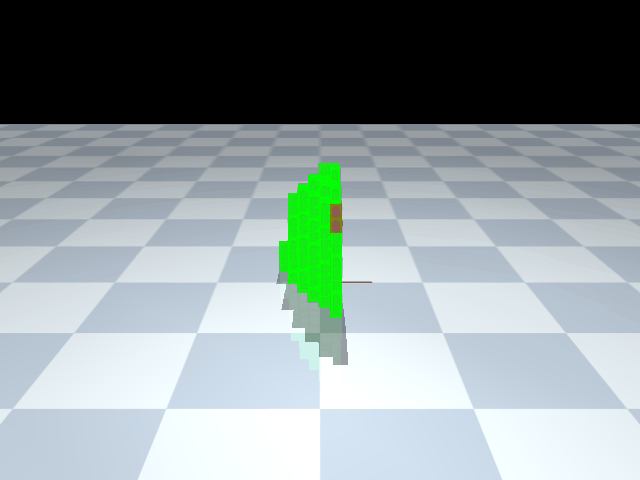

In [4]:
display(Markdown('**pvp_s1 — 1.3201 BL — per-voxel phase, 300 gen (validated lever)**')); display(Image(filename='results/pvp_s1_champion_RUN1/champion.gif' if os.path.exists('results/pvp_s1_champion_RUN1/champion.gif') else 'results/pvp_s1_champion_RUN1.gif')) if (os.path.exists('results/pvp_s1_champion_RUN1/champion.gif') or os.path.exists('results/pvp_s1_champion_RUN1.gif')) else print('gif missing')

**tendon_eg — 1.12 BL (best reproducible) — single-material blob + evolved wave**

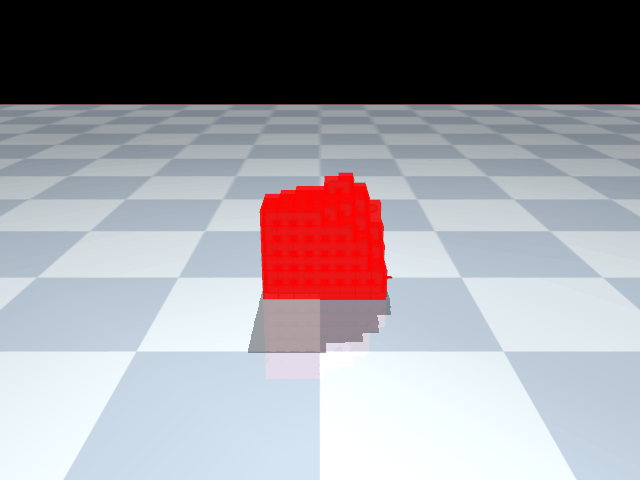

In [5]:
display(Markdown('**tendon_eg — 1.12 BL (best reproducible) — single-material blob + evolved wave**')); display(Image(filename='results/tendon_eg/champion.gif' if os.path.exists('results/tendon_eg/champion.gif') else 'results/tendon_eg.gif')) if (os.path.exists('results/tendon_eg/champion.gif') or os.path.exists('results/tendon_eg.gif')) else print('gif missing')

**tendon_stiff — 1.3057 BL (LUCKY-SEED MAX, not reproduced) — same blob, zero stiff**

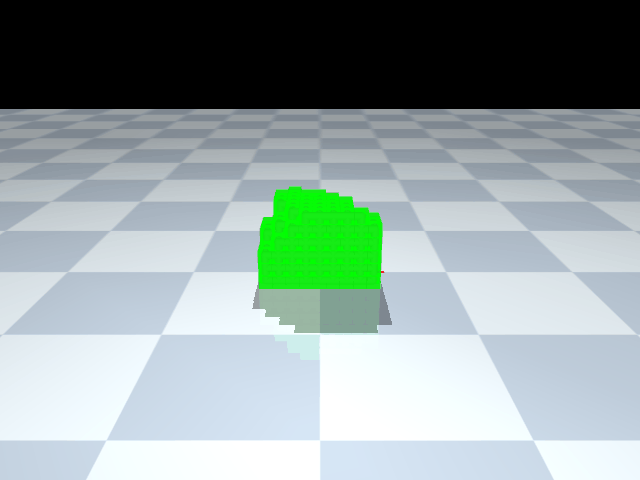

In [6]:
display(Markdown('**tendon_stiff — 1.3057 BL (LUCKY-SEED MAX, not reproduced) — same blob, zero stiff**')); display(Image(filename='results/tendon_stiff/champion.gif' if os.path.exists('results/tendon_stiff/champion.gif') else 'results/tendon_stiff.gif')) if (os.path.exists('results/tendon_stiff/champion.gif') or os.path.exists('results/tendon_stiff.gif')) else print('gif missing')

**tendon_stiff_s2 — 0.7786 BL — same config, seed 2 — same blob, far lower distance**

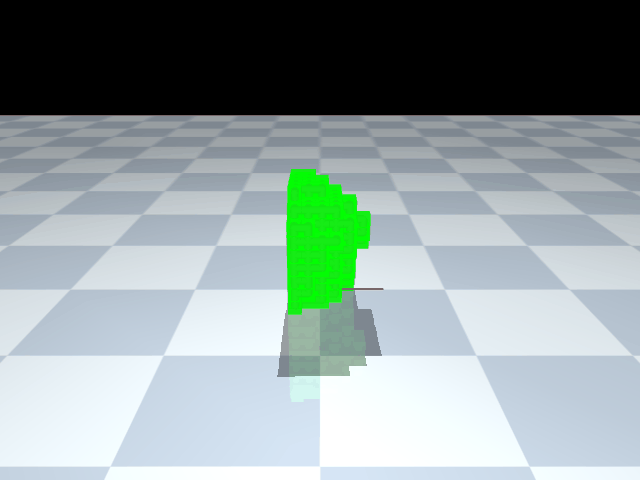

In [7]:
display(Markdown('**tendon_stiff_s2 — 0.7786 BL — same config, seed 2 — same blob, far lower distance**')); display(Image(filename='results/tendon_stiff_s2/champion.gif' if os.path.exists('results/tendon_stiff_s2/champion.gif') else 'results/tendon_stiff_s2.gif')) if (os.path.exists('results/tendon_stiff_s2/champion.gif') or os.path.exists('results/tendon_stiff_s2.gif')) else print('gif missing')

**afpo_stiff — 0.9993 BL — AFPO variant of the same levers — same blob**

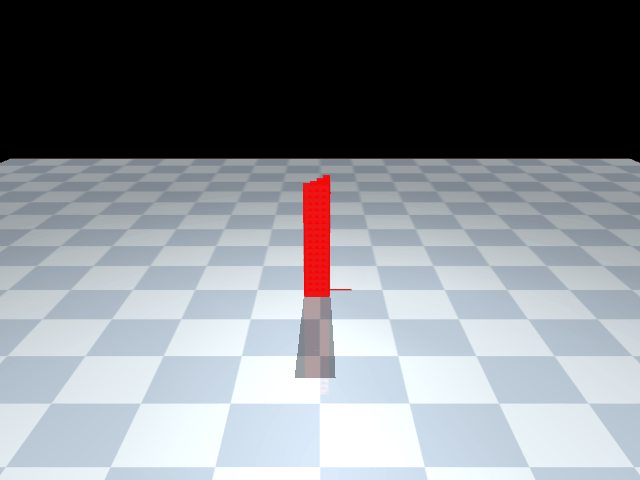

In [8]:
display(Markdown('**afpo_stiff — 0.9993 BL — AFPO variant of the same levers — same blob**')); display(Image(filename='results/afpo_stiff/champion.gif' if os.path.exists('results/afpo_stiff/champion.gif') else 'results/afpo_stiff.gif')) if (os.path.exists('results/afpo_stiff/champion.gif') or os.path.exists('results/afpo_stiff.gif')) else print('gif missing')

## 3b. Per-voxel evolvable phase — the first VALIDATED ceiling-breaker

Every lever above changed the *body* or the *search*. This one changes the **control substrate**:
a **second co-evolving CPPN** maps each voxel's position to its own actuation phase, replacing the
single global 4-gene traveling wave with an arbitrary **spatial phase field** (`--per-voxel-phase`).

Both arms were re-run from scratch after a decoder fix (see 4b), 3 seeds each, pop 50 x gen 300:

| config | seed 1 | seed 2 | seed 3 | **mean max** | **mean top-10** |
|---|---|---|---|---|---|
| evolve-gait control (`egfix`) | 1.0345 | 1.0627 | 1.0392 | 1.046 | 0.969 |
| **per-voxel phase (`pvp`)** | **1.3201** | 1.1038 | 1.1071 | **1.177** | **1.104** |

**Per-voxel phase wins 3/3 seeds on both metrics (+12.6% max, +13.9% top-10) with NO distribution
overlap** — its *worst* seed beats the control's *best* seed on both. That is the strongest outcome
three seeds can give, and it stands in deliberate contrast to the stiff-bias mirage above (same mean,
overlapping, a coin flip). This is the project's first validated architectural win.

**The 1000-generation run.** With a validated lever, a long run was finally justified:
`pvp_long` = per-voxel phase + 500-voxel cap + graded `skip` ground penalty, 1000 generations.

| | max BL | top-10 mean | coverage | QD |
|---|---|---|---|---|
| `pvp_s1` (300 gen, 300 vox) | 1.3201 | 1.1657 | 207/256 | 124.6 |
| **`pvp_long` (1000 gen, 500 vox)** | **1.3384** | **1.2862** | **255/256** | **210.5** |

Read this honestly: **700 extra generations and 67% more voxels bought +1.4% on max fitness**
(1.3201 -> 1.3384). The *archive* improved a lot — top-10 mean +10%, coverage essentially complete
at 255/256 cells — so the run produced a far richer, more uniformly good set of gaits. But the peak
barely moved. Combined with the amplitude probe in 4b, that is the clearest evidence yet that the
ceiling is **not** search-limited.

One correction to an earlier claim in this notebook: `pvp_long` did **not** plateau by generation
150-200. Its max improved as late as generation 846, and its top-10 mean was still rising at 1000.
Long runs do keep paying — just into archive quality rather than peak distance.

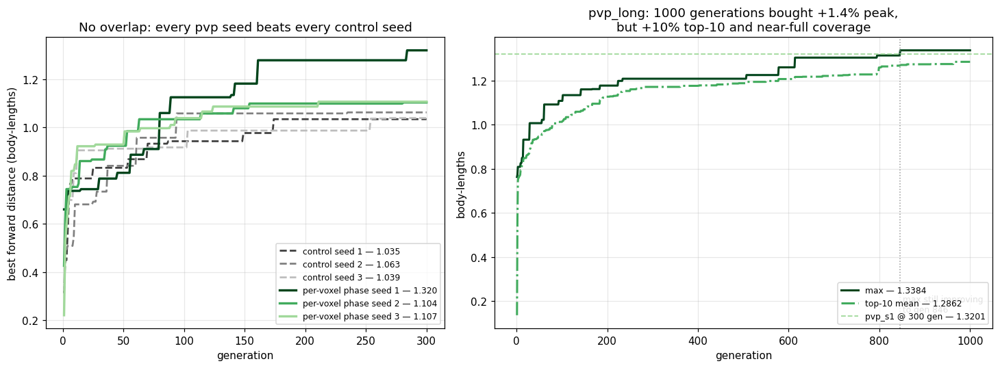

In [9]:
# Per-voxel phase vs control (3 seeds each), and the 1000-generation run.
pvp   = {'pvp_s1': 'seed 1', 'pvp_s2': 'seed 2', 'pvp_s3': 'seed 3'}
egfix = {'egfix_s1': 'seed 1', 'egfix_s2': 'seed 2', 'egfix_s3': 'seed 3'}
greens = ['#00441b', '#41ab5d', '#a1d99b']
greys  = ['#404040', '#808080', '#bdbdbd']

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13.5, 5), gridspec_kw={'width_ratios': [1, 1.25]})

for (n, sd), col in zip(egfix.items(), greys):
    xs, ys = curve(n)
    if xs: axA.plot(xs, ys, color=col, lw=1.8, ls='--', label=f'control {sd} — {max(ys):.3f}')
for (n, sd), col in zip(pvp.items(), greens):
    xs, ys = curve(n)
    if xs: axA.plot(xs, ys, color=col, lw=2.2, label=f'per-voxel phase {sd} — {max(ys):.3f}')
axA.set_xlabel('generation'); axA.set_ylabel('best forward distance (body-lengths)')
axA.set_title('No overlap: every pvp seed beats every control seed')
axA.legend(fontsize=8, loc='lower right'); axA.grid(alpha=.3)

xs, ys  = curve('pvp_long')
xs2, t10 = curve('pvp_long', key='top10_mean')
if xs:
    axB.plot(xs, ys, color='#00441b', lw=2, label=f'max — {max(ys):.4f}')
    axB.plot(xs2, t10, color='#41ab5d', lw=2, ls='-.', label=f'top-10 mean — {t10[-1]:.4f}')
    axB.axvline(846, color='#999', ls=':', lw=1)
    axB.text(846, 0.15, ' max still improving\n to gen 846', fontsize=8, color='#666')
    axB.axhline(1.3201, color='#a1d99b', ls='--', lw=1.2, label='pvp_s1 @ 300 gen — 1.3201')
axB.set_xlabel('generation'); axB.set_ylabel('body-lengths')
axB.set_title('pvp_long: 1000 generations bought +1.4% peak,\nbut +10% top-10 and near-full coverage')
axB.legend(fontsize=8, loc='lower right'); axB.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Key findings (the audit)

**Candidate wins (promising, but see the variance caveat):**
- **`--parent biased`** (breed from strong elites): +1.69x max / +2.2x QD on flex; also lifted
  tendon (1.03 @ gen300 vs the old uniform run's 0.90). Measured on flex multi-seed; on tendon
  single-seed.
- **`--evolve-gait`** (4-gene traveling wave `[kx,ky,kz,offset]` co-evolving with the body):
  wins on flex at 300 gen (1.27x), and gives the best reproducible tendon result (1.12 best-seed).
  Backward-compatible (old genomes fall back to material gait). **Caveat:** on tendon its edge sits
  inside the seed-noise band (seed-2 = 0.98 < material seed-1 = 1.03); the *mechanism* — supplying
  a phase gradient from the control side — is sound, but the tendon margin is unconfirmed.

**Negative results (the most reliable findings here):**
- **`--stiff-bias 0.3` — no reliable effect (DROPPED).** Full multi-seed test: stiff-bias mean
  **1.057** (seeds 1.31 / 0.78 / 1.09) vs matched control mean **1.052** (seeds 1.12 / 0.98).
  Same mean, paired difference −0.01 (a wash), but **2.6x the variance**. The famous 1.3057 was the
  lucky top of that wide distribution, not a real gain. And **all five champions contain zero stiff
  voxels** — the flag has no locomotion mechanism (stiff material can't actuate, so selection deletes
  it). Verdict: adds noise, not distance. Removed from the recommended config.
- **Flex engine** (native MuJoCo deformable): **~140x faster** than tendon, but a **locomotion
  dead-end** — plateaus ~0.03-0.04 BL. Five levers (multi-axis muscles, friction, 2000-gen compute,
  grip feet, voxel resolution) all failed to close the gap. Flex earns its speed by removing the
  per-voxel *contact ratcheting* that crawling depends on.
- **Mass-spring engine** (hand-rolled node masses + springs): ~25x faster than tendon but
  **unstable at usable timesteps** — empirically confirms why MuJoCo uses FEM for deformables.
- **`--fitness forward`** (drop the ground penalty): **null** — byte-identical to the record, because
  the crawlers stay grounded, so the penalty never bound. To get hoppers you must *reward* air-time,
  not merely stop penalising height (and note the bounce descriptor actually *correlates positively*
  with fitness across all archives — bouncier already scores higher, the penalty simply never bites).

**Algorithm comparison:** controlled AFPO-vs-MAP-Elites A/B — AFPO wins at *short* horizons
(gen 60), MAP-Elites' stepping-stone diversity wins *long* (which is why every record is MAP-Elites).

**Two structural findings that now steer the project:**

1. **Seed variance dominates.** On a fixed configuration, best-BL spreads ~**1.7x** between seeds
   (0.78–1.31). That is larger than any lever effect measured in this study, so *every single-seed
   gen-300 comparison here is underpowered.* Going forward: screen levers at **3+ seeds** and treat
   differences under ~1.5x as noise. (The flex/mass-spring negatives are exempt — those are
   order-of-magnitude effects, not margins.)

2. **The plateau is architectural, not compute.** In every run, **max fitness asymptotes by
   generation ~150–200** (e.g. `tendon_stiff_s3` reached 1.067 at iter 87, then only 1.088 by iter
   300 — flat for 200 iterations). QD-score keeps rising because diversity backfills empty cells, but
   the *best* robot is stuck near ~1.1 BL. Implication: **a 2000-generation run at this config will
   very likely not break ~1.1–1.3 BL** — more generations is the weakest available lever. Moving the
   ceiling requires an architecture change (per-voxel evolvable phase, rigid limbs that selection can
   actually keep, or higher actuation authority / elastic energy storage), not more compute.

## 5. Biomechanics context — why the gait looks "buzzy", and how fast is fast?

The champion moves ~**0.45 BL/s** — squarely *limbless-soft-crawler* territory. For scale:

| animal | body-lengths/s | mechanism |
|---|---|---|
| Saharan silver ant | ~108 | legged **gallop** — all legs leave the ground |
| our champion | ~0.45 | limbless soft crawl (friction ratchet) |
| garden snail / slime | ~0.03 | pedal muscular waves + mucus |

An ant is ~3000x faster than a slime *relative to size* because it **leaves the ground** (no
friction drag) and uses jointed leverage. A **frequency sweep** on our champion shows a resonance
peak at ~10-12 Hz (its evolved 10 Hz is optimal; slower is far worse) — so the fast oscillation is
load-bearing, not a mistake. The real ceiling is **structural** (no rigid limbs), not tuning.

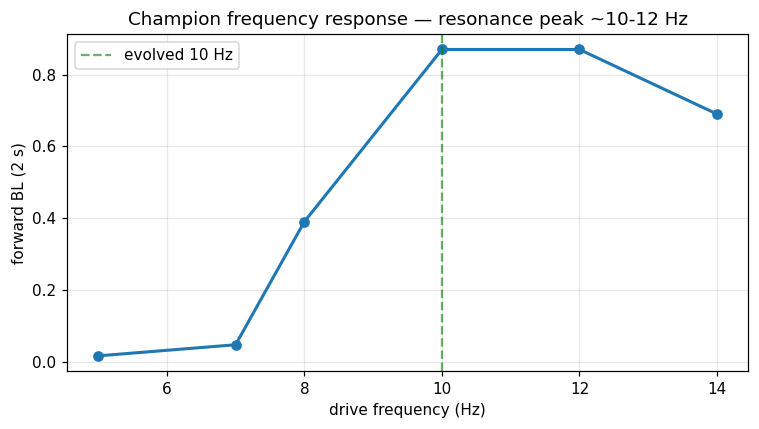

In [10]:
# Frequency response of the record champion (from the freq sweep)
freqs = [5, 7, 8, 10, 12, 14]; fit = [0.016, 0.047, 0.39, 0.87, 0.87, 0.69]
plt.figure(figsize=(7,4))
plt.plot(freqs, fit, 'o-', lw=2); plt.axvline(10, ls='--', c='green', alpha=.6, label='evolved 10 Hz')
plt.xlabel('drive frequency (Hz)'); plt.ylabel('forward BL (2 s)')
plt.title('Champion frequency response — resonance peak ~10-12 Hz'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5b. Physics rework (Sept 2026) — Voxelyze beam bodies (`--body beam`)

**Why.** Our voxels were joined by springs between their **centres**, face neighbours only. A spring
between two points only resists stretching, so the lattice had **no bending, shear or twist
stiffness** — three voxels in a row bend into an L without changing any spring length. That
resistance came *by accident* from the ~7,000 box-box contacts between touching neighbours (and
their 0.6 friction), which were also ~99% of the simulation cost. Voxelyze (Cheney 2013's simulator,
Hiller & Lipson) instead joins neighbours with **Euler-Bernoulli beams** glued to each voxel, so
tilting one voxel bends the bond; bonded voxels never collide.

**Model A — adopted** (`src/physics/mujoco_beam_physics.py`). Voxelyze's bond model applied as forces
inside MuJoCo: a spring on the mismatch between the two voxels' bond midpoints (axial = transverse =
E·L) plus a relative-rotation spring (bending E·L³/12, twist E·L³/(12(1+ν))) — for small
deformations exactly the frame element. Voxelyze damping (bond ζ = 1, global 0.01), Voxelyze
self-collision (surface voxels, ≥ 6 bonds apart, envelope 0.625·size, no friction), Cheney materials
(5 MPa soft/muscle, 500 MPa bone, series average at interfaces), volumetric muscles
(rest length × (1 + mean strain)), floor contact size following muscle strain, per-robot time step.

| validation (tests/test_beam_physics.py) | result |
|---|---|
| cantilever axial / bending / twist vs beam theory | 1.000 / 1.000 / 1.000 (±1%) |
| muscle stroke at 20% | ±0.199 in every direction |
| rigid motion → internal force | 0 (to 1e-6) |
| bond forces sum / torque | 0 / 0 |
| global-damping decay rate | matches ζ·2√(E·L/m) within 1% |
| collision force | series(2EL)·overlap exactly |
| bone vs soft time step | exactly 10× smaller (√100) |

Speed: ~1.2–1.9 ms/step on 485–810-voxel bodies. Soft bodies run 10 cycles in ~9–14 s (vs ~5 min
for the old model), but **bone forces a 10× smaller step**, and ~80% of random robots contain bone.

**Model B — parked** (`prototypes/truss_body_B.py`). Corner-node mass-spring voxels (Evolution-Gym
style cross-bracing in 3D), calibrated to an isotropic material (edges 0.1·E·L, face diagonals
0.2·E·L; Poisson 0.25 is the lattice limit vs Cheney's 0.35). Bulk material and muscles are exact,
and it is ~2× faster than A, but a limb **one voxel thick** is too stiff: bending 1.8×, twist 3.6×
(axial 0.985). Other spring layouts were worse (body diagonals: bending 0.42, twist 31× too soft;
all three kinds: 0.45 / 0.55). Since thin limbs are what we want, B is parked.

**Dropped:** soft MuJoCo *weld* constraints as beams — a soft constraint is not a spring (its static
response is scaled by (1−d)/d ≈ 10× too stiff, and axial/shear/bending stiffness cannot be set
independently).

**Also this month:** a Voxelyze-style **stick-slip floor** (`--friction-static 1.0 --friction-kinetic 0.5`,
Cheney-lab values) and single-μ floors (`--friction`), both floor-only; early-termination controls
(`--early-term-bl`, `--early-term-frac`); a morphology scorecard (`morphology_scorecard.py`). E1 (old
bodies, Cheney floor, 10 cycles): 1.66 BL — the floor changed the *shape* (sparser, a passive tail),
not the speed.

**Pilot `cheney_beam_s1`** (300 generations, 25.7 h, 5.2 min/generation; ran *before* §5c, so without
the volumetric law): best **1.6401 BL** in 10 cycles, top-10 mean 1.2833, 240/256 archive cells. The
champion verified genuine on every check (reproduces exactly; 92% retained after a 2 s settle;
identical at half the step and at Voxelyze's step; steady over 3 s; upright; never more than 24 mm off
the floor). Its **per-cycle speed is unchanged** by the beam rework — 0.164 BL/cycle against 0.166 for
E1's spring bodies — so the gap to Cheney's 0.35–0.40 stayed at ~40–47%. What *did* change is shape:
the first elongated champion (a 10×10×7 wedge, two muscle blocks split by a thin bone wall on a soft
base) and up to 5 separate floor contact patches while walking instead of one slab. Bone was largely
evolved away (archive median 2% against ~25% at random initialisation). The limbs test still fails
(one 99-voxel footprint). See §5c for what the volumetric law then did to this same champion.

## 5c. Volumetric (Poisson) material law + Voxelyze's time step (22 Sept 2026)

**The gap.** §5b's bonds were independent: each one's axial force was `E·L ×` its own extension, so a
voxel's three axes never talked to each other. Voxelyze's material is a real 3D solid (ν = 0.35):

$$\sigma \;=\; \hat E\,\big[(1-\nu)\,\varepsilon_{\text{axial}} + \nu\,(\varepsilon_{t1}+\varepsilon_{t2})\big],
\qquad \hat E = \frac{E}{(1-2\nu)(1+\nu)} = 2.469\,E,$$

and the axial force is **stress × current transverse area**, not stiffness × extension
(`CVX_Material::stress`, `CVX_Link::updateForces`). Each voxel's per-axis strain is the average of its
bonds' shares (`CVX_Voxel::strain(true)`); an axis with fewer than two bonds is free to **bulge**
instead and takes $(1+\sum\varepsilon_{\text{constrained}})^{-\nu}-1$.

The consequences are exactly what was missing:

| situation | response |
|---|---|
| a column free to contract sideways | **E** — the bulge cancels $\hat E$ back down (validated to 0.3%) |
| a voxel squeezed on all three axes (inside a body) | $\hat E(1-\nu)=$ **1.605 E** — 60% stiffer |
| two voxels alone (nothing constrained) | 1.605 E — Voxelyze's own behaviour, not a bug of ours |
| compression | free faces bulge outward, so the bond's area grows and it pushes back harder |

**Time step.** Voxelyze sizes the step per robot from the *stiffest bond and the lightest voxel*:
`recommendedTimeStep = 1/(2π·√(max k_axial / min m))`, times evosoro's `DtFrac` 0.7 — nothing about
the material is fixed in advance, so a robot with bone automatically gets a 10× smaller step than an
all-soft one. `--dt-rule voxelyze` (new default) does exactly this; `ours` is the older estimate that
also sums every bond on a voxel and includes the damping rates. Under the volumetric law
`k_axial = Ê·L`, so the step is √2.469 = 1.57× smaller than it would be without it.

**Validation** (`tests/test_beam_physics.py`, `tests/test_pipeline.py` — 62 tests, all pass).
Beyond §5b's table: Ê and the 1.605 factor against Voxelyze's formulas; the free-bar, long-chain and
solid-block responses; the bulge under compression; the strain split at a soft/bone interface; a
clamped voxel counted as constrained; stress × area reaching `forces()` with the right sign; rigid
motion still force-free; the step rule's exact value and its √Ê and √E scalings; and the pilot's
1.6401 reproduced exactly with `--poisson off --dt-rule ours`.

Two findings worth recording:

1. **A missing torque.** Once the axial force stops being `K·(extension)`, the bond's energy depends on
   the two voxels' *orientations* through the bond axis, and the bond exerts a net torque on the pair
   unless that gradient term is added. It is now applied; it vanishes identically when the law is off
   (measured residual before the fix: 3·10⁻⁴ of the force scale).
2. **The law can run away.** Compressed far enough, the bulge grows without bound and the stress flips
   sign (around ε ≈ −0.8), so a body that crushes itself explodes. This is *structural*, not a step-size
   problem — it is unchanged at 1/16 of the step — and Voxelyze has the same failure (`pow()` of a
   negative base). Measured on 32 bodies: **3 diverge** (of which only one scored anything before).
   Such a run now scores **0** rather than whatever MuJoCo produces after clamping.

**Measured, 32 bodies (16 from the pilot archive, 16 fresh random), full 10 cycles, Cheney floor:**

| | pilot physics | volumetric only | volumetric + Voxelyze step |
|---|---|---|---|
| pilot champion | 1.6401 BL | 1.9147 | **1.9145** |
| mean over 32 | 0.4020 | 0.4236 | 0.4241 |
| total simulation time | 4538 s | 4533 s | **3630 s** |
| diverged | 0/32 | 3/32 | 3/32 |

Voxelyze's step is accurate: against a half step, **+0.6% mean** over the clean bodies and ≤0.3% on every
real evolved body (the 9% outlier is a junk random body scoring 0.19). Net speed **1.25×** (per body
0.87–1.55×: bodies whose step was bone-limited gain 1.4–1.5×, bodies that were already at the 0.5 ms cap
lose a little to the smaller step). So a seed costs roughly **20 h**, not the 10–12 h estimated before the
volumetric law was in.

**Deviation kept deliberately:** Voxelyze splits a bond's strain between its two voxels as
`2ε·r/(1+r) : 2ε/(1+r)` with `r = E_pos/E_neg`, which hands the **stiffer** voxel the larger share — the
opposite of two springs in series. We reproduce it (faithfulness to Cheney); it only touches the Poisson
bookkeeping at soft/bone interfaces, and evolved bodies are ~2% bone.

## 5d. Reading Cheney's own data, and the run log (22–25 Sept 2026)

### The ground truth we had been guessing at

`research_reference/softbots2013Gen1000.tgz` holds **26,164 of Cheney's actual generation-1000
robots**, and every one carries the full simulator configuration. `2013-01-16-10^3-noCost` is our
exact condition: 35 runs × 30 individuals. The `.vxa` files are plain XML (ten `<Layer>` rows of 100
digits), and his material order differs from ours — **1 = muscle+, 2 = soft, 3 = muscle−, 4 = hard**.

**Are his robots limbed? No.** Measured with our own scorecard, his 35 run champions:

| | Cheney | ours (`cheney_vox_s1`) |
|---|---|---|
| voxels | 652 | 564 |
| elongation | 1.00 | 1.00 |
| bodies with ≥ 2 feet | **3 %** | 0 % |
| muscle fraction | **1.00** | 0.82 |
| **footprint** | **26** | **94** |

His no-cost champions are solid blocks of **100 % muscle** with no passive material at all, and they
fail our limbs test too. The differentiated shapes in the paper come from his *cost* conditions
(`costNumActuated` champions: 377 voxels, footprint 4, muscle 0.61). The one real difference is
**footprint** — his bodies are tall and perched, ours squat and flat. His gaits come from the
spatial pattern of actuation phase inside a muscle block, not from limbs.

His penalty, from source: `fitness × (1 − (count / max)^exp)`, count = voxels, muscle voxels or
bonds. His fitness: `|ΔCOM|` in 3-D (undirected, `VX_Sim.cpp:128`) over the **fixed workspace
width** (`HCUBE_SoftbotsExperiment.cpp:392`) — so sideways motion counts and small bodies get no
bonus. Ours is +X over the robot's own bounding box: neither matches. His code also zeroes any run
with fitness > 1000 — the same divergence guard we built independently.

**His algorithm is plain CPPN-NEAT** (`softbotTest.dat`: speciation, compatibility threshold 6,
tournament 2, elitism, population 30, 1000 generations). No archive, no quality-diversity, no AFPO.
**MAP-Elites was our addition, not his.**

### The bug this exposed

Lattice dynamics depend on `E/(ρL²)` and `ρgL/E`. Our scaling corrected for density but silently
assumed the lattice was still his 1 mm; ours is 10 mm, so E needed another factor of 100.
**Our bodies were 200× too soft — 14× too floppy in natural frequency.** Fixed behind
`--materials cheney2013` (soft/muscle 10 MPa, hard 50 MPa — only **5×**, not 100×), which makes
mass, bond stiffness, natural frequency and sag per voxel match his exactly.

Raising gravity to match then exposed a second problem: **MuJoCo's contact stiffness ignores the
material**, so a body sank 2.7 voxels *through* the floor. `--floor-contact voxelyze` installs
Voxelyze's own penalty floor (`k = 2·E·L` per voxel, `CVX_Voxel::floorForce`) via a negative
`solref` pair:

| | gravity | penetration |
|---|---|---|
| old materials, MuJoCo floor | 9.81 | 13.1 % of a voxel |
| Cheney materials, MuJoCo floor | 274.68 | **266.7 %** |
| Cheney materials, Voxelyze floor | 274.68 | **0.8 %** |

### A hypothesis, tested and refuted

We predicted that stiffer bodies would stop splatting and perch like his. **They don't.** Settling
the same bodies with muscles off, footprint from real contacts:

| physics | our bodies | his bodies |
|---|---|---|
| what we had been running | 96 | 48 |
| fully corrected | **96** | **20** |

With the physics right, **his robots reproduce their own published footprint inside our engine**
(20 against his 26) while ours stay flat at 96. So the squat-versus-perched difference is the shape
evolution found, not our physics — and our engine is now validated against his morphology.

### Two things stated wrongly along the way, corrected

- **±39 % actuation strain** — retracted. The paper says "volumetric actuations of **20 %**", about
  6 % linear. Our ±20 % *linear* is roughly 3× larger, not smaller. The code mapping `TempAmp` to a
  temperature is not in the released files, so the config's 39 cannot be converted.
- **"Bone-free bodies run faster" as an argument** — the simulated duration is fixed at 10 cycles;
  only the step count and our wall-clock change, and evolution never sees that.

Gravity −27.468 m/s² (2.8 g) is real: hard-coded in his source, identical in all 26,164 files, with
no justification anywhere in the code or paper.

## 5e. Run log — the volumetric law and the algorithm comparison

All runs below: `--body beam`, volumetric law on, Voxelyze step rule, stick-slip Cheney floor
(1.0 / 0.5), amplitude ±20 %, 10 Hz, 10 cycles measured, population 30, 300 generations,
10³ workspace, early termination 0.02 BL at 50 %. Identical physics throughout, so only the search
differs. All three start from the *same* 30 random robots (generation-1 best 0.5812 in both seed-1
runs — the comparison is properly controlled).

| run | search | best BL | top-10 | cells | notes |
|---|---|---|---|---|---|
| `cheney_beam_s1` (pilot) | MAP-Elites | 1.6401 | 1.2833 | 240 | no volumetric law |
| `cheney_vox_s1` | MAP-Elites | 1.7592 | 1.7206 | 236 | volumetric law on |
| `cheney_vox_s2` | MAP-Elites | 1.9881 | 1.8240 | 163 | |
| **`cheney_neat_s1`** | **CPPN-NEAT** | **2.0195** | 1.3308 | — | **best so far** |

**The algorithm matters more than the physics did.** CPPN-NEAT leads at every checkpoint from
generation 50, and reaches 1.91 by generation 100 — a level MAP-Elites needed all 300 generations to
approach:

| generation | 50 | 100 | 200 | 300 |
|---|---|---|---|---|
| CPPN-NEAT | 1.743 | **1.913** | 2.020 | 2.020 |
| MAP-Elites s1 | 1.611 | 1.653 | 1.759 | 1.759 |
| MAP-Elites s2 | 1.475 | 1.691 | 1.874 | 1.988 |

The trade is exactly what the two methods promise: NEAT builds a better **champion** (2.0195), MAP-Elites
a better **population** (top-10 1.82 against NEAT's 1.33, with 4 of 30 scoring zero). NEAT's peak
then sat flat for its last 120 generations.

**And the NEAT champion is the first one whose shape moves toward Cheney's:**

| | previous champions | NEAT champion | Cheney |
|---|---|---|---|
| voxels | 564–801 | **290** | 652 |
| footprint | 91–100 | **71** | 26 |
| elongation | 1.00 | **1.67** | 1.00 |
| muscle fraction | 0.67–0.82 | **1.00** | 1.00 |

It is 100 % muscle with no soft or hard material, which is his composition exactly. Verified:
reproduces at 2.0195, keeps **99 %** after a 2 s settle (the MAP-Elites champions kept only 80 %),
unchanged with the ground penalty, 2.0273 at a quarter time step, and dead linear over three seconds
(2.020 / 4.029 / 6.011 BL). That is **0.202 BL per cycle, 51–58 % of Cheney's 0.35–0.40**, up from
41–47 % before this month's work. The limbs test still fails — one foot, as in every run including his.

**Divergence is steady and handled.** The volumetric law is non-linear in compression: past roughly
80 % compression the stress flips sign and a body that crushes itself explodes. This is structural,
not a step-size problem — it is unchanged at 1/16 of the step, and Voxelyze has the same failure.
Such runs score 0. Rate: 4.2 % of 9,000 evaluations, flat across a whole run (evolution does not
learn to avoid it).

## 5f. Cheney's own parameters, a floor bug, and the record (26 Sept – 1 Oct 2026)

### Reading his config exposed a scaling bug of ours

Lattice dynamics are fixed by two dimensionless groups: `E/(ρL²)` (natural frequency) and `ρgL/E`
(sag per voxel). Our material scaling corrected for density but silently assumed the lattice was
still his 1 mm; ours is 10 mm, so E needed another factor of `(L_ours/L_his)² = 100`.
**Our bodies had been 200× too soft — 14.1× too floppy in frequency.**

`--materials cheney2013` applies the full correction (soft/muscle 10 MPa, hard 50 MPa — only **5×**,
not the 100× evosoro implies). Mass, bond stiffness, natural frequency and sag per voxel then match
his simulation exactly. With it, 10 cycles at his 40 Hz is a 0.25 s window instead of 1.0 s, so
evaluations are **1.8× cheaper** despite a 3× smaller time step, and **nothing diverged** in a
30-robot pilot (the volumetric law's blow-ups need deformations that stiff bodies never reach).

### Then a floor bug of mine invalidated a whole run

`cheney_corr_s1` reached **4.1204 BL** and never plateaued — close to Cheney's own median of 4.39.
It was wrong, and the cause was `--floor-contact voxelyze` as I first wrote it. It set
`pair_solref = (-k, -c)` with `k = 2·E·L`, on the belief that MuJoCo reads a negative solref as
stiffness and damping in N/m. **It does not — those values act in acceleration space.** Pressing a
single resting voxel with a known force and comparing against the exact penalty-spring prediction
`F/k`:

| materials | measured ÷ F/k |
|---|---|
| evosoro | 1.91 |
| **cheney2013** | **14.33** |

A clean constant factor, growing with material stiffness. The deeper cause of the *dynamic* failure
was separate and sharper: **MuJoCo's contact softness is a time constant (20 ms by default), and a
40 Hz cycle is 25 ms**, so the contact never builds force before the cycle reverses. Static
penetration had been fine all along; only the gait failed.

I first blamed the actuation amplitude. **That was wrong too** — an amplitude sweep gave 1.02 voxels
of penetration at ±6% and 1.67 at ±20%: barely scaling, so a floor-independent baseline of ~1 voxel
was doing the damage.

**The fix** is a hard floor — `FLOOR_TIMECONST = 0.5 ms`, 2% of a 40 Hz cycle, critically damped,
floored at 2.5 time steps for stability. Voxelyze's own penalty floor is effectively hard at these
loads (under 1% of a voxel), so hard contact is the faithful choice.

| | before | after |
|---|---|---|
| peak penetration while walking, median | 1.78 voxels | **0.12** |
| peak penetration, worst of 16 bodies | 2.67 | **0.16** |
| cost per step | 0.826 ms | **0.823 ms** |

**What it cost:** `cheney_corr_s1`'s champion scores **−1.33 BL** on a correct floor — it goes
backwards. Both its 4.12 and its exciting near-Cheney footprint (29 against his 26) were artefacts of
a body partly inside the ground. Its gait had also died by cycle 40, a second reason it should not
have been believed.

### The record, and a clean plateau

| run | generations | best BL | top-10 | note |
|---|---|---|---|---|
| `cheney_neat_s1` | 300 | 2.0195 | 1.33 | old physics |
| `cheney_corr_s1` | 300 | ~~4.1204~~ | — | **invalid** (soft floor) |
| **`cheney_fix_s1`** | 300 | **2.6118** | 1.59 | corrected physics + fixed floor |
| `cheney_fix600_s1` | 600 | **2.6118** | 1.83 | same champion body, byte-identical |

**2.6118 BL verified**: reproduces exactly, 2.6160 at a quarter time step, unchanged with the ground
penalty, **super-linear over 30 cycles** (2.61 / 5.51 / 8.18 — it does not slow down), penetration 15%
of a voxel, worst bond strain 0.34 against an instability at 0.8, no divergence. That is
**0.261 BL per cycle, about 59% of Cheney's median run champion** — our best honest comparison.

**And doubling the generations changed nothing.** 2.6118 arrived at generation 287 and stayed flat for
**313 generations**, returning the byte-identical body. The population consolidated (top-10 1.59 → 1.83,
dead robots 5 → 2) while the peak did not move. This configuration is converged; more generations are
not the lever.

### Morphology: what survived the floor fix

| | `cheney_neat_s1` | `cheney_fix_s1`/600 | Cheney |
|---|---|---|---|
| voxels | 290 | 370 | 652 |
| footprint | 71 | **70** | **26** |
| elongation | 1.67 | 1.43 | 1.00 |
| muscle fraction | 1.00 | **1.00** | **1.00** |

Footprint ~70 is where **both honest runs** land, old physics and new — so the near-Cheney footprint
did not survive. The one thing that now reproduces reliably is **100% muscle, no passive material**,
which is exactly his champions' composition. The limbs test still fails (one foot) — as it does for
him, where only 3% of champions pass it.

### Process notes worth keeping

- A finished AFPO/NEAT run **deletes its own checkpoint**, so it cannot be extended by resuming; 600
  generations meant re-treading the first 300 (which reproduced identically, confirming determinism).
- I piped a multiprocessing script through stdin on Windows **twice**. Spawn re-imports `__main__`,
  the workers respawn forever, and the orphans ran for 45 hours. They also slowed `cheney_fix_s1` by
  ~40% (175 s/generation against 101 s once cleared) — a slowdown I had wrongly dismissed by reasoning
  from the one process still alive afterwards rather than the sixteen running at the time.

## 5g. The two-stage protocol on beam bodies (2 – 8 Oct 2026)

**Why:** `cheney_fix_s1` converged (2.6118 flat for 313 generations) with 30 distinct genomes and steady
diversity, and its gait parameters were already optimal. The diagnosis was a needle peak: the body had
co-adapted to the fixed material gait. Mertan & Cheney 2024 fix this with two stages (§3b): evolve
the body under a fixed controller, then evolve control on the frozen bodies. On springs it gave +123%.

### Stage 1 — `beamstage1_s1` (MAP-Elites, 300 iterations, shape descriptors, muscle-fraction cost, `--evolve-size`)

The morphology broke open, the speed did not:

| | `cheney_fix_s1` | `beamstage1_s1` archive |
|---|---|---|
| muscle fraction (median) | 1.00 | **0.29** |
| bodies using all three materials | — | **72 / 176** |
| footprint (median) | 70 | **11** |
| elongation (max) | 1.43 | **3.00** |
| fastest body, untaxed | **2.6118** | 1.6208 |

The run's own champion (1.0920 taxed, 1.2251 BL untaxed) is **11% muscle on a footprint of 3** — a shape
no earlier run produced.

### Building stage 2 for beam bodies

- The control CPPN's per-voxel phase field is **added to** the material gait (`--phase-mode offset`,
  the default); replacing it scored 0.0000 on beam bodies.
- **The first warm start wrecked the bodies:** a fresh full-range control net took the stage-1 bodies
  from 1.62 to **0.09 BL** before stage 2 could start. Fix: an **evolvable gain** on the control net,
  starting small (`--phase-gain-init 0.05`), log-normal mutation, bounded 0.001–1.
- **A silent bug caught before launch:** `CPPNGenome._clone` copies an *explicit* list of attributes, so
  the new gain was dropped on every copy and reverted to full range. Added to `_clone`, with a test.
  91 tests pass.

### Stage 2 — `beamstage2_s1` (300 iterations, frozen bodies, control only)

| | start (stage-1 bodies, gain 0.05) | end | change |
|---|---|---|---|
| best | 1.6696 | **2.2684** | **+36%** |
| top-10 mean | 1.5159 | **1.8270** | **+21%** |

On springs, stage 2 had given +3.4%; with the gain gene it is worth +21–36% here. Across the top ten the
gain evolved from 0.05 to between 0.095 and 0.74 (champion 0.40). Body by body, the evolved gait beats the same body's material gait
by a median **1.16×** across the top 10, and **1.44×** on the champion (1.5783 → 2.2684).
**Still 13% below the 2.6118 plateau.**

### Verifying the champion — it turns

Body: **743 voxels, a full 10×10×10 box, fill 0.74**, footprint 37, 55% muscle / 45% soft / no bone.
In size and fill that is Cheney's best robot (761 voxels, 10³, fill 0.76).

Reproduces exactly; 2.2702 at a quarter time step; no divergence; penetration 13% of a voxel; worst
bond strain 0.59; early termination irrelevant. **But it scores 0 after 40 cycles of walking.**
Tracked cycle by cycle, it has not stopped: it keeps ~0.23 BL/cycle along a **curving path**, its
heading swinging ~2° per cycle, so after ~45 cycles it walks sideways. It also walks tilted
(uprightness 0.53, steady from cycle 2 on).

Forward (+X) BL gained per 10-cycle window — window 1 is what fitness scores:

| robot | w1 | w2 | w3 | w4 | w5 | w6 |
|---|---|---|---|---|---|---|
| stage-2 champion (743 vox) | 2.27 | 2.18 | 1.76 | 1.04 | −0.01 | −0.90 |
| same body, material gait | 1.58 | 1.50 | 1.24 | 0.78 | 0.35 | 0.05 |
| stage-2 #3 (327 vox) | 1.88 | 1.97 | 1.94 | 1.92 | 1.90 | 1.88 |
| stage-2 #5 (540 vox) | 1.75 | 2.02 | 2.02 | 2.02 | 2.02 | 2.02 |
| plateau `cheney_fix_s1` | 2.61 | 2.89 | 2.67 | 2.32 | 1.80 | 1.03 |

**Lesson:** a 10-cycle +X window cannot see turning. Two of the top five (#3, #5) walk dead straight
for 60 cycles, upright — the most durable gaits we have, though slower in window 1.

**The plateau record turns too.** Top-down paths (`results/beamstage2_s1/paths_60cycles.png`) show
`cheney_fix_s1`'s champion curving the same way; its "69% retention after 40 cycles" was turning,
not a slowing gait. **Not an engine bias:** mirrored in y it turns the other way (cycle 30:
(+8.18, −2.19) → (+8.30, +1.89) workspace widths); mirrored in x it walks −x with the same y. So the
engine is left-right symmetric and turning belongs to the robots. Net displacement over 60 cycles,
in workspace widths: plateau 16.0, #5 11.9, #3 11.6, champion 11.5.

### Why do top robots use so few voxels? (asked 8 Oct)

- **Nothing caps it.** The lattice is 10³ with trimming off; stage 1's size gene spans the full
  0.05–1.00 range in the archive; the muscle cost is a fraction, so it is size-neutral.
- **Size barely predicts speed — for us or for Cheney.** Rank correlation, voxels vs score: stage-2
  archive +0.13 (BL) / +0.33 (metres); Cheney's 35 run champions +0.48 (no cost) / +0.19 (cost on
  actuated voxels — which shrank his bodies to a median 377).
- **Two things in our setup lean small.** (1) BL divides by the body's *own* longest side, so a body
  shorter than 10 voxels gets a 10/L bonus Cheney's fixed-width metric does not give: stage-2 #2 is
  6 voxels long and 120 voxels in all, scoring 2.04 BL from 0.122 m — **1.22** on Cheney's scale.
  (2) The MAP-Elites shape grid keeps elongated and sparse bodies on purpose, and an elongation-*e* body
  fits at most 1000/*e* voxels of a 10³ box.
- And the new champion is the biggest body in the archive's top ten (743 voxels).
- **How big is the short-body bonus?** Exactly 10/L. 35% of stage-2 bodies (43% of stage-1) are shorter
  than 10 voxels and get 1.11× (L = 9) up to 2.0–2.5× (L = 4–5); 4 of each top ten benefit, and
  re-ranking on a fixed width would swap 3–4 of them. Both champions are 10 long, so unaffected.
  Whether it is "too big" depends on whether speed scales with length — BL assumes it does. Decision
  (8 Oct): switch selection to **Cheney's own score**, |ΔCOM| (3D) / fixed 10-voxel width, any
  direction. On robots we already have it changes almost nothing (all four reference robots are 10
  long and walk +X: champion 2.2684 → 2.2817, plateau 2.6118 → 2.6149); what changes is what
  selection can see — short bodies lose the bonus, and −X or sideways walkers stop scoring 0.

## 5h. Cheney's own score (8 Oct 2026)

**What his code does.** `HCUBE_SoftbotsExperiment.cpp`: `fitness = |FinalCOM_Dist| / (BoundingBoxLength
× VoxelSize)`, with BoundingBoxLength 10 and FixedBoundingBoxSize 10, so the divisor is a **fixed 10 mm
workspace width**. Voxelyze's `FinalCOM_Dist = (GetCM() − IniCM).Length()` — a **3D** vector length,
vertical included, any direction. *One open point:* in the single Voxelyze file in the archive, `IniCM`
is only ever set to (0,0,0); the code that would set it to the starting centre of mass is not in the
archive. The paper (§3.4) says "the difference in the center of mass … between initialization and the
end of 10 actuation cycles", so the start position is used here.

**Built as two independent switches** (so a later run can tell which change mattered):

| flag | default (unchanged) | Cheney |
|---|---|---|
| `--direction` | `forward`: +X component | `any`: 3D length |
| `--divide-by` | `body`: own longest side → **BL** | `workspace`: `--grid-size` voxels → **W** |

`--early-term-bl` is compared with the score itself, so with Cheney's score it means 0.02 W in any
direction. Defaults are byte-identical: the record champion still scores 2.6118 BL, and **2.6149 W**
on Cheney's score. 14 new tests (105 in all) pass.

**Pilot (2 generations, real settings) — two things worth knowing:**
- **Generation 1 doubled: 1.3356 W against the record run's 0.6625 BL.** The best robot walks at
  113°, mostly sideways — it scored 0 on the forward score. Headings in the population are spread
  all round the compass; selection can now see all of them.
- **Early termination almost never fires any more**: 1 of 30 robots is under 0.02 W in any direction
  by cycle 5, against 17 of 30 under 0.02 BL forward. Generations cost ~150 s instead of ~101 s, so
  300 generations take ~12.5 h, not 8.5 h.
- Vertical COM change by cycle 5: median +0.004 W, range −0.26 to +0.16 W (toppling bodies) —
  small against walkers, as the 3D-vs-floor preview predicted.

**Run `cheney_score_s1`** (launched 8 Oct 13:32): `cheney_fix_s1`'s exact command (CPPN-NEAT,
`--no-age-pareto --parent biased`, seed 1, 300 generations, 10³, no muscle cost, 40 Hz, 10 cycles,
corrected materials, hard floor, stick-slip) plus `--direction any --divide-by workspace`. The one
change is the score, so its result compares directly with 2.6118 and — for the first time on his
own metric — with Cheney's 35 run champions (median 4.39, mean 4.61, range 3.39–5.95). Other
differences from his setup remain (search details, damping, engine; §5d/§5f), so it is the same
yardstick, not yet the same experiment.

### Result (finished 8 Oct 23:10, ~9.6 h): **2.7170 W — a new record on both scores**

| | `cheney_fix_s1` (old score) | **`cheney_score_s1`** (Cheney's score) |
|---|---|---|
| Cheney's score (W) | 2.6149 | **2.7170** (+3.9%) |
| old score (+X / own length, BL) | 2.6118 | **2.6955** (+3.2%) |
| net distance over 60 cycles (W) | 15.99 | **17.58** (+10%) |
| peak reached at generation | 286 | 296 |

**Verified:** reproduces exactly; 2.7175 at a quarter time step; early termination irrelevant;
scored after 40 cycles of walking it gets **2.9972 (110% — it speeds up after the start)**; per
10-cycle window 2.72 then ~3.0 W, steady; uprightness 0.92; penetration 15% of a voxel; worst bond
strain 0.32; no divergence. It walks almost straight along +X (heading −7° in the scored window,
curving gently to −31° by cycle 60), so the any-direction score changed what selection *could*
reward, not where this champion goes.

**Body:** 284 voxels, bounding box 6×9×10, fill 0.53, footprint 55, one foot, **100% muscle**
(85 / 199 in the two phases) — the same family as the previous record (370 voxels, footprint 70,
100% muscle). Final population: top-10 mean 1.89 W, no zeros; top-10 bodies 284–611 voxels.

**Against Cheney:** 2.72 W is **62% of his median run champion (4.39)**, up from 60% (2.61 W) for the
previous record, measured on his own score this time. Still single-seed, and still improving at
the end (peak at generation 296), like the previous record was at 300 — which then stayed flat
for 313 more generations.

## 6. Methods (brief)

- **Encoding:** CPPN+NEAT genome maps voxel position (x,y,z,dist) -> presence + material
  {1,2 = muscle phase 0/180, 3 = soft, 4 = stiff}; 20x20x20 grid, capped at 300 voxels.
- **Physics:** `--body springs` (default) = free rigid body per voxel + spatial-tendon muscles;
  `--body beam` = Voxelyze beam bonds (§5b); flex = native deformable (fast, weak). Floor:
  `--friction MU` or `--friction-static/--friction-kinetic` (stick-slip).
- **Search:** MAP-Elites over a 16x16 gait archive (mean COM height x vertical bounce), or AFPO.
- **Fitness:** `max(0, forward_+X / body_length) x ground_fraction`.
- **New CLI levers (all additive, default = legacy):** `--parent {uniform,biased,curiosity}`,
  `--evolve-gait`, `--fitness {directed,forward,efficiency,stable}`, `--stiff-bias F`,
  `--gait {material,wave}`, `--flex`.

## 7. Next steps

The ceiling near ~1.1 BL is **architectural** (§4), and the champions prove why: the body has
collapsed to an interchangeable blob and the **gait genes do all the work**. So the priority is to
enrich control and structure, not to run longer or tune the body-material knob.

1. **Per-voxel evolvable phase (highest upside).** A second CPPN outputs a phase offset *per voxel*,
   replacing the 4-gene global wave. This gives evolution a spatially-rich actuation pattern — the
   most direct way to break past the single-blob solution — while staying backward-compatible
   (versioned genome). *Scoping this as the next spike.*
2. **Rigid limbs that selection can keep.** `--stiff-bias` failed because stiff voxels can't actuate
   and get deleted. The fix is to make rigidity *pay*: reward leg-like protrusions, or attach
   actuators across stiff segments so a lever earns thrust. Harder, but the only route to leaving the
   ground.
3. **Reward air-time.** A `--fitness airtime` mode to actively seed hoppers/gallopers (the ant
   strategy), with a realism check — the ground penalty was guarding against ballistic cheats, and
   bounce already correlates positively with fitness, so this needs care not just a sign flip.
4. **Fix the methodology.** Screen every future lever at 3+ seeds; report mean ± spread, not
   single-seed maxes. Only after a lever clears the ~1.5x noise bar is a long (2000-gen) run worth
   the ~9 days of compute.